# Breast Cancer — treinamento e inferência

Classificação do atributo `Class` da [base UCI Breast Cancer, ID 14](https://archive.ics.uci.edu/dataset/14/breast+cancer): `no-recurrence-events` ou `recurrence-events`.
São 286 registros e nove atributos. O alvo representa **recidiva**, não a distinção entre tumor benigno e maligno.

Execute as células em ordem. O notebook cria os módulos reutilizáveis `treinamento.py` e `inferencia.py`, compara seis classificadores e um baseline e salva o melhor pipeline por acurácia média na validação cruzada.
Os dados são baixados da UCI quando não estão na pasta `dados`.


In [1]:
%pip -q install pandas==2.2.3 numpy==2.3.5 scikit-learn==1.8.0 matplotlib==3.10.8 joblib==1.5.3

## 1. Módulo de treinamento

Imputação pela moda e codificação one-hot ficam dentro do pipeline, ajustadas somente nos dados de treino de cada fold. O grau de malignidade é tratado como categoria.

Há perfis de atributos repetidos na base. Eles são preservados, pois não existe identificador de paciente, e agrupados para não aparecerem simultaneamente em treino e validação/teste. Um fold externo fica reservado para o teste (aproximadamente 20%); os demais passam por validação cruzada estratificada por grupos em cinco folds.


In [2]:
%%writefile treinamento.py
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import json

import joblib
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


SEED = 42
TARGET = 'Class'
CLASSES = ['no-recurrence-events', 'recurrence-events']
URL = 'https://archive.ics.uci.edu/static/public/14/breast+cancer.zip'
DATA_SHA256 = 'ca7d3fa97b62ff967b6894ffbb3acaaf4a51062e0149e5950b3ad6f685970b65'
DOMINIOS = {
    'age': [f'{i}-{i + 9}' for i in range(10, 100, 10)],
    'menopause': ['lt40', 'ge40', 'premeno'],
    'tumor-size': [f'{i}-{i + 4}' for i in range(0, 60, 5)],
    'inv-nodes': [f'{i}-{i + 2}' for i in range(0, 36, 3)] + ['36-39'],
    'node-caps': ['yes', 'no'],
    'deg-malig': ['1', '2', '3'],
    'breast': ['left', 'right'],
    'breast-quad': ['left-up', 'left-low', 'right-up', 'right-low', 'central'],
    'irradiat': ['yes', 'no'],
}
CAMPOS = list(DOMINIOS)


def carregar_dados(caminho='dados/breast-cancer.data'):
    caminho = Path(caminho)
    if caminho.exists():
        conteudo = caminho.read_bytes()
    else:
        with urlopen(URL, timeout=60) as resposta:
            with ZipFile(BytesIO(resposta.read())) as arquivo:
                conteudo = arquivo.read('breast-cancer.data')
        caminho.parent.mkdir(parents=True, exist_ok=True)
        caminho.write_bytes(conteudo)

    if sha256(conteudo).hexdigest() != DATA_SHA256:
        raise ValueError('O arquivo não corresponde à base Breast Cancer UCI 14.')

    return pd.read_csv(
        BytesIO(conteudo), names=[TARGET, *CAMPOS], na_values='?', dtype=str,
    )


def definir_busca():
    return [
        {'modelo': [DummyClassifier(strategy='most_frequent')]},
        {
            'modelo': [LogisticRegression(max_iter=2000, random_state=SEED)],
            'modelo__C': [0.01, 0.1, 1, 10],
        },
        {
            'modelo': [KNeighborsClassifier()],
            'modelo__n_neighbors': [3, 5, 9, 15],
            'modelo__weights': ['uniform', 'distance'],
        },
        {
            'modelo': [SVC(random_state=SEED)],
            'modelo__C': [0.1, 1, 10],
            'modelo__kernel': ['linear', 'rbf'],
        },
        {
            'modelo': [DecisionTreeClassifier(random_state=SEED)],
            'modelo__max_depth': [2, 4, None],
            'modelo__min_samples_leaf': [2, 5, 10],
        },
        {
            'modelo': [RandomForestClassifier(n_estimators=200, random_state=SEED)],
            'modelo__max_depth': [3, 6, None],
            'modelo__min_samples_leaf': [2, 5],
        },
        {'modelo': [BernoulliNB()], 'modelo__alpha': [0.1, 1, 10]},
    ]


def treinar(dados, pasta_saida='artefatos'):
    X, y = dados[CAMPOS], dados[TARGET]
    grupos = pd.util.hash_pandas_object(X.fillna('?'), index=False)
    divisao = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    treino, teste = next(divisao.split(X, y, groups=grupos))
    X_treino, X_teste = X.iloc[treino], X.iloc[teste]
    y_treino, y_teste = y.iloc[treino], y.iloc[teste]

    pipeline = Pipeline([
        ('imputacao', SimpleImputer(strategy='most_frequent')),
        ('codificacao', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ('modelo', DummyClassifier()),
    ])
    validacao = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    busca = GridSearchCV(
        pipeline, definir_busca(), scoring='accuracy', cv=validacao,
        n_jobs=1, refit=True, error_score='raise',
    )
    busca.fit(X_treino, y_treino, groups=grupos.iloc[treino])

    resultados = pd.DataFrame(busca.cv_results_)
    resultados['modelo'] = [
        type(parametros['modelo']).__name__ for parametros in resultados['params']
    ]
    comparacao = (
        resultados.sort_values('rank_test_score', kind='stable')
        .drop_duplicates('modelo')
        .rename(columns={
            'mean_test_score': 'acuracia_cv',
            'std_test_score': 'desvio_cv',
            'rank_test_score': 'posicao',
        })[['modelo', 'acuracia_cv', 'desvio_cv', 'posicao']]
        .reset_index(drop=True)
    )

    modelo = busca.best_estimator_
    predicoes = modelo.predict(X_teste)
    parametros = {
        chave.removeprefix('modelo__'): valor
        for chave, valor in busca.best_params_.items() if chave != 'modelo'
    }
    metricas = {
        'modelo': type(modelo.named_steps['modelo']).__name__,
        'parametros': parametros,
        'acuracia_cv': float(busca.best_score_),
        'acuracia_teste': accuracy_score(y_teste, predicoes),
        'acuracia_balanceada_teste': balanced_accuracy_score(y_teste, predicoes),
        'precisao_recidiva': precision_score(
            y_teste, predicoes, pos_label=CLASSES[1], zero_division=0,
        ),
        'recall_recidiva': recall_score(
            y_teste, predicoes, pos_label=CLASSES[1], zero_division=0,
        ),
        'f1_recidiva': f1_score(
            y_teste, predicoes, pos_label=CLASSES[1], zero_division=0,
        ),
        'n_treino': len(treino),
        'n_teste': len(teste),
        'seed': SEED,
        'sklearn': sklearn.__version__,
        'relatorio': classification_report(
            y_teste, predicoes, labels=CLASSES, output_dict=True, zero_division=0,
        ),
    }
    artefato = {
        'pipeline': modelo, 'campos': CAMPOS, 'dominios': DOMINIOS,
        'campos_anulaveis': ['node-caps', 'breast-quad'],
        'classes': CLASSES, 'metricas': metricas,
    }
    pasta = Path(pasta_saida)
    pasta.mkdir(parents=True, exist_ok=True)
    joblib.dump(artefato, pasta / 'modelo.joblib')
    comparacao.to_csv(pasta / 'comparacao.csv', index=False)
    (pasta / 'metricas.json').write_text(
        json.dumps(metricas, ensure_ascii=False, indent=2), encoding='utf-8',
    )
    return {
        'artefato': artefato, 'comparacao': comparacao, 'metricas': metricas,
        'matriz_confusao': confusion_matrix(y_teste, predicoes, labels=CLASSES),
        'indices_treino': treino, 'indices_teste': teste,
    }


Overwriting treinamento.py


In [3]:
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

from treinamento import CAMPOS, CLASSES, carregar_dados, treinar

dados = carregar_dados()
display(dados.head())
print(f'Registros: {len(dados)} | Atributos: {len(CAMPOS)}')
display(pd.DataFrame({
    'ausentes': dados.isna().sum(),
    'categorias': dados.nunique(),
}))
display(dados['Class'].value_counts().rename('quantidade').to_frame())
print(f'Linhas idênticas: {dados.duplicated().sum()}')
print(f'Perfis repetidos: {dados[CAMPOS].duplicated().sum()}')


Registros: 286 | Atributos: 9
Linhas idênticas: 14
Perfis repetidos: 20


,Class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


,ausentes,categorias
Class,0,2
age,0,6
menopause,0,3
tumor-size,0,11
inv-nodes,0,7
node-caps,8,2
deg-malig,0,3
breast,0,2
breast-quad,1,5
irradiat,0,2


,quantidade
Class,
no-recurrence-events,201
recurrence-events,85


## 2. Treinamento e seleção

`GridSearchCV` escolhe os hiperparâmetros e o modelo pela acurácia média dos cinco folds de treino. Em empate, prevalece a primeira configuração da busca. O baseline sempre prevê a classe majoritária. O teste externo não participa da escolha.


,modelo,acuracia_cv,desvio_cv,posicao
0,DecisionTreeClassifier,0.7626,0.0409,1
1,RandomForestClassifier,0.7498,0.0497,2
2,BernoulliNB,0.7498,0.0457,3
3,KNeighborsClassifier,0.7457,0.0464,4
4,SVC,0.7407,0.0412,12
5,LogisticRegression,0.7281,0.0559,15
6,DummyClassifier,0.7018,0.0085,30


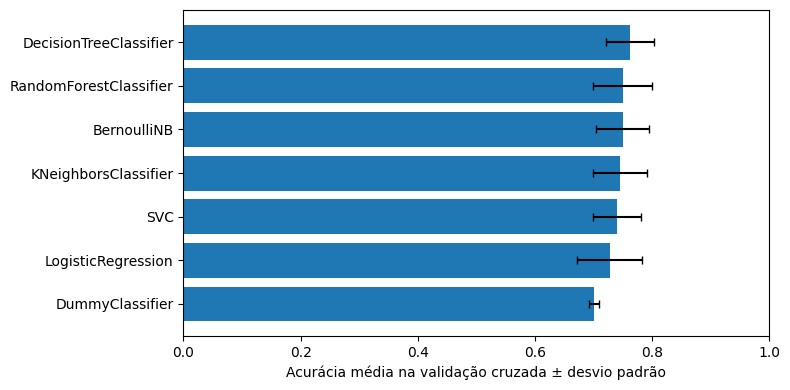

In [4]:
resultado = treinar(dados)
comparacao = resultado['comparacao']
display(comparacao.round(4))

plt.figure(figsize=(8, 4))
plt.barh(
    comparacao['modelo'][::-1], comparacao['acuracia_cv'][::-1],
    xerr=comparacao['desvio_cv'][::-1], capsize=3,
)
plt.xlabel('Acurácia média na validação cruzada ± desvio padrão')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


## 3. Avaliação do melhor modelo

A acurácia é o critério solicitado. Como há mais casos sem recidiva, também são apresentados precisão, recall, F1 da classe `recurrence-events`, acurácia balanceada e matriz de confusão. A média da validação é usada para seleção e pode ser otimista após a busca; a avaliação final é a do teste reservado.


Melhor modelo na validação: DecisionTreeClassifier
Hiperparâmetros: {'max_depth': 2, 'min_samples_leaf': 10}
Treino: 228 | Teste: 58


,valor
acuracia_cv,0.7626
acuracia_teste,0.7414
acuracia_balanceada_teste,0.5933
precisao_recidiva,0.6667
recall_recidiva,0.2353
f1_recidiva,0.3478


,precision,recall,f1-score,support
no-recurrence-events,0.7500,0.9512,0.8387,41.0000
recurrence-events,0.6667,0.2353,0.3478,17.0000
accuracy,0.7414,0.7414,0.7414,0.7414
macro avg,0.7083,0.5933,0.5933,58.0000
weighted avg,0.7256,0.7414,0.6948,58.0000


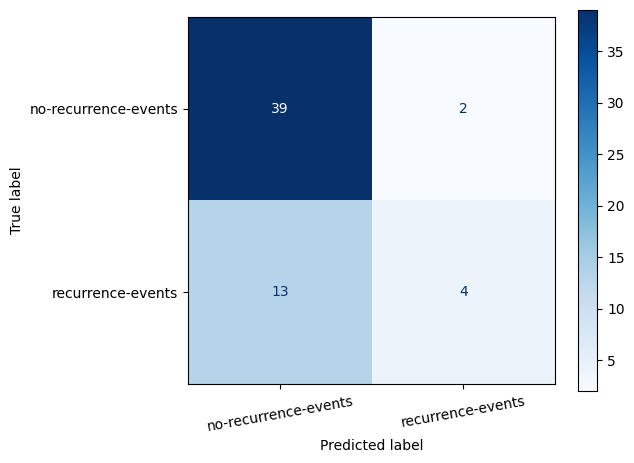

In [5]:
metricas = resultado['metricas']
print(f"Melhor modelo na validação: {metricas['modelo']}")
print(f"Hiperparâmetros: {metricas['parametros']}")
print(f"Treino: {metricas['n_treino']} | Teste: {metricas['n_teste']}")
display(pd.Series({
    chave: valor for chave, valor in metricas.items()
    if chave.startswith(('acuracia', 'precisao', 'recall', 'f1'))
}, name='valor').to_frame().round(4))
display(pd.DataFrame(metricas['relatorio']).T.round(4))

ConfusionMatrixDisplay(
    resultado['matriz_confusao'], display_labels=CLASSES,
).plot(cmap='Blues', values_format='d')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## 4. Módulo de inferência

Informe os nove atributos nas categorias da UCI. `node-caps` e `breast-quad` aceitam `None` ou `?`; esses valores recebem a moda aprendida no treino. Campos ausentes, extras ou categorias inválidas geram erro. O modelo salvo inclui o pré-processamento e pode ser carregado sem novo treinamento. Carregue apenas arquivos `joblib` de origem confiável.


In [6]:
%%writefile inferencia.py
from collections.abc import Mapping

import joblib
import numpy as np
import pandas as pd


def preparar_paciente(paciente, artefato):
    if not isinstance(paciente, Mapping):
        raise ValueError('Informe a paciente como um dicionário.')

    campos = artefato['campos']
    faltantes = sorted(set(campos) - set(paciente))
    extras = sorted(set(paciente) - set(campos))
    if faltantes or extras:
        raise ValueError(f'Campos ausentes: {faltantes}. Campos desconhecidos: {extras}.')

    valores = {}
    for campo in campos:
        valor = paciente[campo]
        if not pd.api.types.is_scalar(valor):
            raise ValueError(f'{campo}: informe apenas um valor.')
        ausente = pd.isna(valor) or str(valor).strip() in ('', '?')
        if ausente:
            if campo not in artefato['campos_anulaveis']:
                raise ValueError(f'{campo}: preenchimento obrigatório.')
            valores[campo] = np.nan
            continue
        valor = str(valor).strip()
        if valor not in artefato['dominios'][campo]:
            raise ValueError(f'{campo}: valor inválido {valor!r}.')
        valores[campo] = valor

    return pd.DataFrame([valores], columns=campos)


def inferir(paciente, caminho_modelo='artefatos/modelo.joblib'):
    artefato = joblib.load(caminho_modelo)
    entrada = preparar_paciente(paciente, artefato)
    classe = str(artefato['pipeline'].predict(entrada)[0])
    return {
        'Class': classe,
        'indicativo': {
            'no-recurrence-events': 'Sem evento de recidiva previsto',
            'recurrence-events': 'Evento de recidiva previsto',
        }[classe],
    }


Overwriting inferencia.py


In [7]:
from inferencia import inferir

nova_paciente = {'age': '50-59',
 'menopause': 'ge40',
 'tumor-size': '25-29',
 'inv-nodes': '0-2',
 'node-caps': 'no',
 'deg-malig': 2,
 'breast': 'left',
 'breast-quad': 'left-low',
 'irradiat': 'no'}

inferir(nova_paciente)

{'Class': 'no-recurrence-events',
 'indicativo': 'Sem evento de recidiva previsto'}

## 5. Resultado e arquivos gerados

A árvore de decisão (`max_depth=2`, `min_samples_leaf=10`) obteve **76,26% de acurácia média na validação** e **74,14% no teste reservado** (43 de 58 casos). O recall de recidiva foi **23,53%** (4 de 17 casos): a acurácia não representa boa detecção de todos os eventos de recidiva. A saída de inferência conserva o rótulo original `Class`. O pipeline salvo foi ajustado apenas no treino, correspondendo ao modelo avaliado no teste.

- `artefatos/modelo.joblib`: pipeline, categorias, campos e métricas.
- `artefatos/comparacao.csv`: melhor configuração de cada família na validação.
- `artefatos/metricas.json`: métricas do modelo escolhido no teste.

Uso acadêmico: a base é pequena e histórica; a classificação não constitui diagnóstico clínico.

**Fonte:** Zwitter, M. & Soklic, M. (1988). *Breast Cancer*. UCI Machine Learning Repository. DOI: [10.24432/C51P4M](https://doi.org/10.24432/C51P4M). Dados sob licença CC BY 4.0.
